## Pegasus Evaluation: Depth and Load

Sections B.3 and B.4 of the evaluation of the paper. The evaluation is split into `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2, B.2b), `2c_depth_and_load.ipynb` (B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). `2a_base_case.ipynb` describes
the two data sources, the setup (A) and the metrics and methods (B.1) that every notebook uses; the parameters are
defined once in `pegasus/evaluation_setup.py`. The real data does not support either experiment yet (B.3 and B.4 say why), so this notebook runs on synthetic
data, with the synthetic base case of B.1. B.3 varies the depth of a map-reduce application (fork-join trees of the
services of B.1), B.4 the load and the arrival pattern of the chain of B.1.

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "synthetic"   # the real data does not support B.3 and B.4 yet (`skipped`), so this notebook uses synthetic data

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/evaluation_cache/ (written by 2a_base_case.ipynb), or
# computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 computed and saved to statics\evaluation_cache\b1_synthetic_7326db4e14cd1cb4.joblib
synthetic data, 3 seeds: chain s1 -> s2 -> s3, per seed 50 training configurations per service and 100 held-out configurations, poisson arrivals at 4/s


## B. Coverage and Tightness of Service Bounds

The metrics, the methods and the rule *validity before tightness* are those of B.1 (`2a_base_case.ipynb`).

### B.3 Varying Depth of a Map-Reduce Application

- **Synthetic:** fork-join trees of the three services of B.1, balanced with 1 to 8 levels (1 to 255 services) and
  narrow with 5 to 8 levels.
- **Real:** skipped, not yet measured: the testbed campaign of these trees is specified in `new_experiments.md` (B3)
  but not yet run.
- **Baselines:** as in B.1 without DNN Sum, each extended from a chain to a tree as described below.

**The application.** A tree of services, in the map-reduce style of `new_experiments.md` (B3): the leaves (the
detectors) alternate between $s_1$ and $s_2$, and every inner service, including the root, is the aggregator $s_3$;
$s_1$, $s_2$ and $s_3$ are the generated services of the chain of B.1 under the same seed. An arriving frame (item) is
sent to all leaves at the same moment. An aggregator waits until both of its children have released the frame (the
frame is then *complete* at the aggregator) and processes the complete frames in the order of their arrival (FIFO). One
frame is therefore one item at every service, and every service receives the same arrival rate $\lambda$ (frames/s).
The end-to-end latency of a frame is the time from its arrival until the root releases it.

**The hierarchies.** A *balanced* tree with $h$ levels (`tree_levels`) has $N = 2^h - 1$ services and $P = 2^{h-1}$ paths
from a leaf to the root, each with $h$ services. A *narrow* tree with $h$ levels (`narrow_levels`) has a chain of $h - 1$
aggregators, each joining the one below it with one new leaf: the same longest path of $h$ services, but only
$N = 2h - 1$ services and $P = h$ paths. For example, at $h = 8$ the balanced tree has 255 services and 128 paths, the
narrow tree 15 services and 8 paths. Comparing the two at the same $h$ separates the effect of depth from that of breadth.

**Setting (synthetic data).** Every service has one worker (Assumption 2 of the paper). The arrivals are Poisson, and the
arrival rate of every held-out configuration is set so that the slowest service of the tree has the utilization
`tree_utilization`: $\lambda = u / \max_k m_k$, with $u$ = `tree_utilization` and $m_k$ the true mean execution time of
service $k$ at that configuration (s). The fixed rate of B.1 would overload some configurations, because every service
of a tree receives every frame. The execution times of a frame are independent between the services, as in B.1. For
every seed, the training configurations, the training data of $s_1$ to $s_3$ and the held-out configurations are those of
B.1 (the code checks this), except that every configuration has one worker; the GPs are fitted anew for every tree on
these data, and the ground truth is simulated anew for every tree (`synthetic_tree_data` in `pegasus/data.py`).

**From a chain to a tree.** At a service with one worker, frame $j$ is released at $R(j) = \max\big(C(j), R(j-1)\big) + Y(j)$,
where $C(j)$ is the time at which frame $j$ is complete at the service (its arrival time at a leaf; the later of the
two release times of the children at an aggregator), $R(j-1)$ the release time of the frame before it, and $Y(j)$ the
execution time of frame $j$ at the service (all in s). These operations are only maxima and sums, so the release time at
the root is a maximum over leaf-to-root paths of the release time that the root would have if that path ran as a
separate chain with the same arrivals and execution times: $D(j) = \max_p D_p(j)$, with $D(j)$ the end-to-end latency of
frame $j$ in the tree and $D_p(j)$ its latency through path $p$ run as a chain. The wait for the other branch is
contained in the maximum. The data code checks this identity frame by frame on every tree of up to 15 services. If
every path has a bound $d_p$ with $P(D_p > d_p) \le \varepsilon / P$, then $P(D > \max_p d_p) \le \varepsilon$ (union bound
over the paths), whatever the dependence between the paths, which share services and arrivals. Every method is
extended in this way (`compare_tree_methods` in `pegasus/evaluation.py`):
- *Pegasus Node:* the union bound of every path over its node bounds; there are $\sum_p K_p$ (path, service) pairs, with
  $K_p$ the number of services on path $p$, so every node bound is computed at $\varepsilon / \sum_p K_p$. Every service
  is bounded with the external arrivals.
- *Pegasus SNC:* the network service curve of every path at $\varepsilon / P$.
- *GP Sum* (at $\varepsilon$ per path, a point prediction) and *GP Queue* (every service at $\varepsilon$, added along
  the path): as in B.1 on every path.
- *Quantile Union, Conformal, Oracle:* every one of the $N$ services at $\varepsilon / N$ (the union bound over the services),
  added along every path. Quantile Union and Conformal are trained on every service monitored alone under the arrival
  rate that the tree has at a training configuration, with that rate as a further input.

The tree gets the largest value over its paths. A larger tree thus pushes every node bound of Pegasus Node further into
the tail ($\varepsilon / \sum_p K_p$, e.g. $\varepsilon / 1024$ at $h = 8$), while Pegasus SNC splits $\varepsilon$ only once per path.

**Complexity (against the size of the tree).** Training time and evaluation time are defined in B.1 (Metrics).
- *Training.* Every method trains one model per service type, and every tree with $h \ge 2$ has the same three types,
  so the training time is expected to stay constant.
- *Evaluation.* Every node bound and every path is computed on its own, also where two have the same service types, so
  the times are those of a tree of different services: Pegasus Node computes one node bound per service and child
  ($N$ in all) and grows with $N$; Pegasus SNC computes one network service curve per path, $P$ paths of $h$ services,
  and grows with $P h$.

**Figures.** Four separate figures. The first three are over the number of levels $h$ of the balanced tree (in
parentheses after every level: its number of services $N$); the fourth shows the narrow trees in the same way as the first. The two time figures sit side by side in the
width of one, each with its own vertical axis; there is no room for $N$ at every tick, so their ticks give only
$h$; the first figure gives $N$ for every $h$. Every line is the
median over the seeds, and the band around it reaches from the smallest to the largest seed; the legend of every figure
sits inside it where it hides the fewest points.
- *Tightness*, for every seed the median over its held-out configurations. The horizontal line at 1× is the measured
  quantile; in the red area below it a method is under the measured quantile and is no bound. A filled marker means
  that the method holds at that tree (it reaches the confidence level under every seed, as defined in B.1), and a
  hollow marker that it does not. Look at the markers first: only lines with filled markers are bounds whose tightness
  can be compared.
- *Training time* (s, logarithmic), one line per set of trained models; the legend names the methods that use these
  models.
- *Evaluation time* (s, logarithmic), one line per method.
- *Tightness on the narrow trees*, as the first figure. Compare it with the first figure at the same $h$: the narrow
  tree has the same depth but far fewer services and paths.

In [2]:
if "B.3" in skipped:
    print("B.3 skipped: not supported by the {} data".format(data_source))
else:
    # B.3: fork-join trees of the services of B.1 (pegasus/trees.py), balanced and narrow
    trees = {**{("balanced", h): balanced_tree(h) for h in tree_levels}, **{("narrow", h): narrow_tree(h) for h in narrow_levels}}

    def compute():
        tree_truth, tree_methods, tree_seconds = {}, {}, {}   # (shape, levels) -> (levels, seed) -> ...
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for s in seeds:
                for (shape, levels), (children, path) in trees.items():
                    data = synthetic_tree_data(children, path, level=1 - alpha, node_level=1 - alpha / len(path), coverage_check=coverage_check,
                                               seed=[seed, s], utilization=tree_utilization, service_seed=s)
                    # the configurations and training data of B.1, every configuration with one worker
                    assert same_configurations(model_inputs(data.x_test, data.workers_column), model_inputs(bases[s].x_test, bases[s].workers_column)), \
                        "the held-out configurations differ from those of B.1"
                    assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.y_train), "the training data differs from that of B.1"
                    assert_unseen(data)
                    models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                    tree_methods.setdefault(shape, {})[(levels, s)], tree_seconds.setdefault(shape, {})[(levels, s)] = compare_tree_methods(
                        data, models, alpha, confidence, n_calibration, model_seed=seed + s, leave_out=only_base_case)
                    tree_truth.setdefault(shape, {})[(levels, s)] = (data.measured, data.measured_low)
                print(f"seed {s}: {len(trees)} trees evaluated")
        return dict(tree_truth=tree_truth, tree_methods=tree_methods, tree_seconds=tree_seconds)

    globals().update(cached("b3_trees", data_source, compute, inputs=dict(tree_levels=tree_levels, narrow_levels=narrow_levels,
                                                                           tree_utilization=tree_utilization)))

seed 0: 12 trees evaluated


seed 1: 12 trees evaluated


seed 2: 12 trees evaluated
b3_trees: results computed and saved to statics\evaluation_cache\b3_trees_synthetic_8a6b4b390f0b5f07.joblib


B.3 balanced fork-join trees, synthetic data: leaves s1, s2, aggregators s3, one worker each, 100 held-out configurations per seed,
poisson arrivals at 50% utilization of the slowest service, 3 seeds


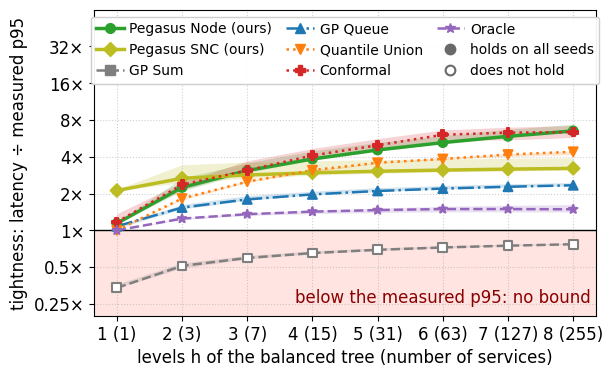

legend_inside: the legend hides 9 points or bands at its best location (upper center)


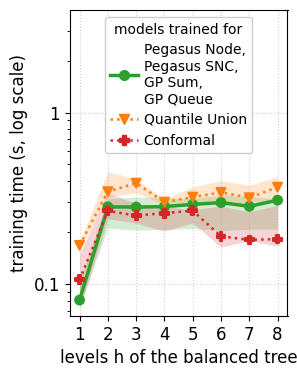

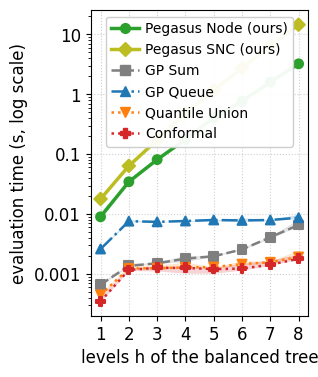

B.3 narrow fork-join trees, synthetic data: leaves s1, s2, aggregators s3, one worker each, 100 held-out configurations per seed,
poisson arrivals at 50% utilization of the slowest service, 3 seeds


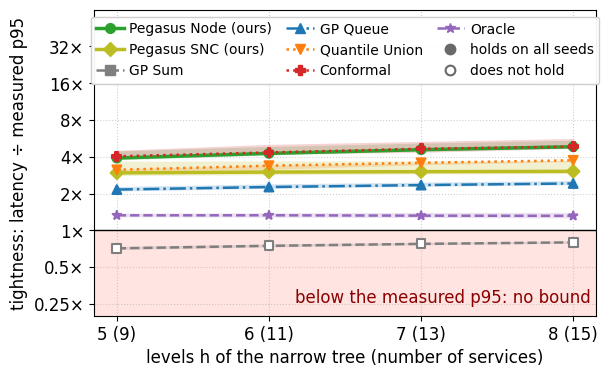

In [3]:
if "B.3" in skipped:
    print("B.3 skipped: not supported by the {} data".format(data_source))
else:
    tree_statistics = {shape: sweep_statistics(tree_methods[shape], tree_truth[shape], levels, seeds, confidence)   # shape -> name -> coverage, tightness, holds, computed
                       for shape, levels in (("balanced", tree_levels), ("narrow", narrow_levels))}
    tree_times = sweep_seconds(tree_seconds["balanced"], tree_levels, seeds)                                        # name -> training, evaluation
    size_ticks = lambda shape, levels: [f"{h} ({len(trees[(shape, h)][1])})" for h in levels]   # one row: the fixed layout of every figure
    title = lambda shape: (f"B.3 {shape} fork-join trees, {data_source} data: leaves s1, s2, aggregators s3, one worker each, "
                           f"{len(base.measured)} held-out configurations per seed,\n{workload['process']} arrivals at {tree_utilization:.0%} utilization "
                           f"of the slowest service, {len(seeds)} seeds")
    tightness_and_time_figure(tree_levels, tree_statistics["balanced"], tree_times, "levels h of the balanced tree (number of services)",
                              title("balanced"), p_label, tick_labels=size_ticks("balanced", tree_levels), log_x=False, name=f"b3_trees_{data_source}",
                              # the two time figures side by side in the width of one: too narrow for "h (N)" at every tick, and the
                              # tightness figure already gives N for every h
                              time_halves=("levels h of the balanced tree", [str(h) for h in tree_levels]))
    tightness_sweep_figure(narrow_levels, tree_statistics["narrow"], "levels h of the narrow tree (number of services)", title("narrow"), p_label,
                           tick_labels=size_ticks("narrow", narrow_levels), log_x=False, name=f"b3_narrow_trees_{data_source}_tightness")

In [4]:
if "B.3" in skipped:
    print("B.3 skipped: not supported by the {} data".format(data_source))
else:
    services_text = lambda n: f"{n} service" + ("s" if n > 1 else "")
    tree_label = lambda shape: lambda h: f"h = {h} ({services_text(len(trees[(shape, h)][1]))})"
    # median over the seeds of the tightness of a method on one tree; a seed without a finite tightness counts as infinitely loose
    typical = lambda shape, levels, name, h: np.median(np.nan_to_num(tree_statistics[shape][name]["tightness"][levels.index(h)], nan=np.inf))
    deepest = narrow_levels[-1]
    breadth = "; ".join(f"{name} {typical('balanced', tree_levels, name, deepest):.2f}× balanced and {typical('narrow', narrow_levels, name, deepest):.2f}× narrow"
                        for name in pegasus_versions)
    display(Markdown(
        f"**What this shows** ({data_source} data, ε = {alpha:g}, {len(seeds)} seeds).\n\n*Balanced trees.*\n"
        + sweep_conclusion(tree_levels, tree_statistics["balanced"], sweep_competitors, tree_label("balanced")) + "\n"
        + ground_truth_conclusion(tree_levels, tree_truth["balanced"], tree_statistics["balanced"], seeds, tree_label("balanced"), p_label,
                                  ", at the same services, configurations and utilization") + "\n"
        + time_conclusion(tree_levels, tree_times, sweep_competitors, tree_label("balanced"))
        + "\n\n*Narrow trees.*\n"
        + sweep_conclusion(narrow_levels, tree_statistics["narrow"], sweep_competitors, tree_label("narrow")) + "\n"
        + f"- **Depth against breadth.** At h = {deepest} the balanced tree has {len(trees[('balanced', deepest)][1])} services and the narrow tree "
        f"{len(trees[('narrow', deepest)][1])}, with paths of the same length. Tightness (median over the seeds): {breadth}. The difference is the cost of "
        f"breadth: the further split of ε over more paths and services."
    ))

**What this shows** (synthetic data, ε = 0.05, 3 seeds).

*Balanced trees.*
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours), Pegasus SNC (ours), GP Queue, Quantile Union, Conformal. Methods that do not hold, and where: GP Sum at every setting.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 1.14× at h = 1 (1 service) to 6.52× at h = 8 (255 services); Pegasus SNC (ours) from 2.12× at h = 1 (1 service) to 3.22× at h = 8 (255 services); GP Queue from 1.08× at h = 1 (1 service) to 2.34× at h = 8 (255 services); Quantile Union from 1.00× at h = 1 (1 service) to 4.40× at h = 8 (255 services); Conformal from 1.17× at h = 1 (1 service) to 6.37× at h = 8 (255 services).
- **Ground truth.** The measured p95 of the end-to-end latency, the median over the held-out configurations, goes from 0.23 s at h = 1 (1 service) to 0.78 s at h = 8 (255 services), at the same services, configurations and utilization. The Oracle, the union bound over measured services, is at 1.00× and 1.49×.
- **Training time** (median over the seeds; methods that share their models are named together): Pegasus Node (ours), Pegasus SNC (ours), GP Sum, GP Queue 0.081 s at h = 1 (1 service) and 0.31 s at h = 8 (255 services); Quantile Union 0.17 s at h = 1 (1 service) and 0.37 s at h = 8 (255 services); Conformal 0.11 s at h = 1 (1 service) and 0.18 s at h = 8 (255 services).
- **Evaluation time** (median over the seeds): Pegasus Node (ours) 0.009 s at h = 1 (1 service) and 3.2 s at h = 8 (255 services); Pegasus SNC (ours) 0.018 s at h = 1 (1 service) and 14 s at h = 8 (255 services); GP Sum 0.00067 s at h = 1 (1 service) and 0.0066 s at h = 8 (255 services); GP Queue 0.0026 s at h = 1 (1 service) and 0.0087 s at h = 8 (255 services); Quantile Union 0.00045 s at h = 1 (1 service) and 0.0019 s at h = 8 (255 services); Conformal 0.00035 s at h = 1 (1 service) and 0.0018 s at h = 8 (255 services).

*Narrow trees.*
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours), Pegasus SNC (ours), GP Queue, Quantile Union, Conformal. Methods that do not hold, and where: GP Sum at every setting.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 3.91× at h = 5 (9 services) to 4.83× at h = 8 (15 services); Pegasus SNC (ours) from 2.95× at h = 5 (9 services) to 3.04× at h = 8 (15 services); GP Queue from 2.16× at h = 5 (9 services) to 2.42× at h = 8 (15 services); Quantile Union from 3.13× at h = 5 (9 services) to 3.74× at h = 8 (15 services); Conformal from 4.04× at h = 5 (9 services) to 4.84× at h = 8 (15 services).
- **Depth against breadth.** At h = 8 the balanced tree has 255 services and the narrow tree 15, with paths of the same length. Tightness (median over the seeds): Pegasus Node (ours) 6.52× balanced and 4.83× narrow; Pegasus SNC (ours) 3.22× balanced and 3.04× narrow. The difference is the cost of breadth: the further split of ε over more paths and services.

### B.4 Varying Load and Arrival Pattern

- **Synthetic:** the load (any arrival rate, B.4a) and the variability of the arrivals (renewal arrivals with
  gamma-distributed gaps of any squared coefficient of variation $C^2$, B.4b). Batching and diurnal arrivals are not
  implemented.
- **Real:** skipped (B.4a and B.4b). The campaign measured every run under Poisson arrivals at one rate that it set
  for that run, so neither the load nor the arrival pattern can be changed.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal need every service monitored at every load and
  arrival pattern; the execution-time baseline and the proposed method do not.

B.4 has two parts. B.4a changes how many items arrive per second (the load), and B.4b changes how evenly the items
arrive at the same rate (the arrival pattern).

**Setting of both parts.** For every seed, the chain, the training configurations, the per-service execution-time
models and the held-out configurations of B.1. Execution times do not depend on the arrivals, so these models are
used unchanged. Only the arrival process at the first service changes, and the ground truth is simulated anew for
every setting.

What each method knows about the arrivals: both versions of Pegasus are given the arrival process (they use the moment
generating function of the gap between two arrivals), and GP Queue is given the arrival rate and $C^2$. Quantile Union
and Conformal are trained anew for every setting, on each service monitored alone under the arrival process of that
setting. GP Sum ignores the arrivals, so its latency is the same in every setting.

#### B.4a Load

**Setting (synthetic data).** Poisson arrivals as in B.1, with the arrival rate $\lambda$ (items/s), one value of `loads` per
setting. The rate of B.1 is one of them, and that setting is the base case again. The *utilization* of a service at a
configuration is $\rho = \lambda \cdot$ (mean execution time of the service at that configuration, in seconds) ÷ (its
number of workers): the share of the time in which every worker of the service is busy. At $\rho \geq 1$ items arrive faster than the service processes them,
its queue grows without limit, and no latency quantile exists. The rates are therefore chosen so that no service is
overloaded at any held-out configuration under any seed; the code checks this with the true mean execution times of
the generated services. The *busiest service* of a chain at a configuration is the service with the largest
utilization.

**What to expect.** The waiting time at a service grows without limit as its utilization approaches 1 (in the Allen-Cunneen
formula through the factor $1 / (1 - \rho)$). With a higher rate, the queues therefore make up a larger part of the
latency; GP Sum ignores that part. Both versions of Pegasus bound a service with the pessimistic mean of its execution
time, which lies above the true mean. Where the utilization computed with the pessimistic mean reaches 1, they give no
finite bound, although the service is stable.

**Figure.** The horizontal axis is the arrival rate $\lambda$ (items/s). The utilization of the busiest service at every
rate, the median over the held-out configurations of all seeds, is printed above the figure. The vertical axis is the tightness, for every seed
the median over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every
line is the median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled
marker means that the method holds at that rate (it reaches the confidence level under every seed, as defined in
B.1), a hollow marker that it does not. A seed under which a method gives no finite latency at half of the held-out
configurations or more counts as infinitely loose, and the method has no point where that is the case for half of the
seeds or more. Look at the markers first, then at whether the filled lines move away from 1× toward the higher rates.

In [5]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    # B.4a: the chains of B.1 under Poisson arrivals of different load (`loads`: arrival rate with synthetic data, utilization of the busiest service with real data)
    base_load = workload["rate"] if data_source == "synthetic" else base_utilization
    assert base_load in loads, "the load of B.1 is not one of the settings"
    # Training runs per service. Real data: more than in B.1, because close to saturation a bound only exists if the mean execution
    # time is known precisely (see the text above). Synthetic data: the models of B.1.
    load_n_train = n_pool if data_source == "real" else n_train

    def compute():
        load_methods, load_truth, load_models, load_y_train = {}, {}, {}, {}   # (load, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge); seed -> models / their training data
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for load in loads:
                for s in seeds:
                    data = chain_data(s, n_train=load_n_train, **{load_option: load})
                    assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                    if s not in load_models:   # the execution times do not depend on the arrivals, so every load uses the same per-service models
                        load_models[s], load_y_train[s] = (base_models[s] if load_n_train == n_train else fit_services(
                            data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)), data.y_train
                    assert all(np.array_equal(data.y_train[name], load_y_train[s][name]) for name in data.path), "the training data differs between the loads"
                    load_methods[(load, s)], _ = compare_methods(data, load_models[s], data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                                 model_seed=seed + s, leave_out=only_base_case, x_train_load=data.x_train_load)
                    load_truth[(load, s)] = (data.measured, data.measured_low)
        return dict(load_methods=load_methods, load_truth=load_truth, load_models=load_models, load_y_train=load_y_train)

    globals().update(cached("b4a_load", data_source, compute, inputs=dict(loads=loads, load_option=load_option, load_n_train=load_n_train)))
    # true utilization of the busiest service per held-out configuration, the seeds one after the other; with real data it is the load itself
    load_utilization = {load: np.concatenate([busiest_utilization(base.path, bases[s].x_test, load, service_seed=s) for s in seeds])
                        if data_source == "synthetic" else np.full(len(base.measured), load) for load in loads}
    assert max(utilization.max() for utilization in load_utilization.values()) < 1, "a service is overloaded at a held-out configuration"
    print(f"{len(load_methods)} combinations of load and seed evaluated.")

b4a_load: results computed and saved to statics\evaluation_cache\b4a_load_synthetic_d37e13397a684311.joblib
15 combinations of load and seed evaluated.


utilization of the busiest service, median over the held-out configurations of all seeds: 0.03 at 1/s, 0.07 at 2/s, 0.10 at 3/s, 0.13 at 4/s, 0.16 at 5/s
B.4a load, synthetic data: s1 → s2 → s3, 100 held-out configurations per seed,
poisson arrivals, 3 seeds


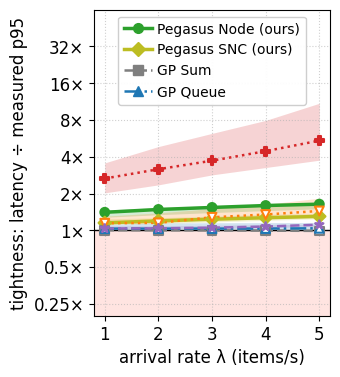

In [6]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    load_statistics = sweep_statistics(load_methods, load_truth, loads, seeds, confidence)   # name -> coverage, tightness, holds, computed
    # one short label and one row of ticks, because B.4a and B.4b sit side by side in the width of one figure; the utilization
    # of the busiest service at every rate is printed instead of drawn
    load_axis = "arrival rate λ (items/s)" if data_source == "synthetic" else "utilization of the busiest service"
    if data_source == "synthetic":
        print("utilization of the busiest service, median over the held-out configurations of all seeds: "
              + ", ".join(f"{np.median(load_utilization[load]):.2f} at {load:g}/s" for load in loads))
    tightness_sweep_figure(loads, load_statistics, load_axis,
                           f"B.4a load, {data_source} data: {' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed,\n"
                           f"{workload['process']} arrivals, {len(seeds)} seeds", p_label,
                           tick_labels=[f"{load:g}" for load in loads], log_x=False, name=f"b4a_load_{data_source}", half="left")

In [7]:
if "B.4a" in skipped:
    print("B.4a skipped: not supported by the {} data".format(data_source))
else:
    display(Markdown(
        f"**What this shows** ({data_source} data, {workload['process']} arrivals, ε = {alpha:g}, {len(seeds)} seeds).\n"
        f"- **Load.** Utilization of the busiest service over the held-out configurations of all seeds: "
        + "; ".join(f"median {np.median(load_utilization[load]):.2f} and maximum {load_utilization[load].max():.2f} at {load_label(load)}"
                    for load in (loads[0], loads[-1])) + ".\n"
        + sweep_conclusion(loads, load_statistics, sweep_competitors, load_label)
        + f"\n- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): "
        + "; ".join(f"{name} " + ", ".join(f"{finite_share(load_methods, name, load, seeds):.0%} at {load_label(load)}" for load in loads)
                    for name in pegasus_versions)
        + ". Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded at that "
        f"load, although its true utilization is below 1.\n"
        + ground_truth_conclusion(loads, load_truth, load_statistics, seeds, load_label, p_label, ", for the same services and configurations")
    ))

**What this shows** (synthetic data, poisson arrivals, ε = 0.05, 3 seeds).
- **Load.** Utilization of the busiest service over the held-out configurations of all seeds: median 0.03 and maximum 0.16 at 1/s; median 0.16 and maximum 0.80 at 5/s.
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours), Pegasus SNC (ours), Conformal. Methods that do not hold, and where: GP Sum at every setting; GP Queue at every setting; Quantile Union at every setting.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 1.41× at 1/s to 1.64× at 5/s; Pegasus SNC (ours) from 1.15× at 1/s to 1.30× at 5/s; Conformal from 2.66× at 1/s to 5.43× at 5/s.
- **Finite bounds.** Share of the held-out configurations at which a version of Pegasus gives a finite latency (median over the seeds): Pegasus Node (ours) 100% at 1/s, 100% at 2/s, 100% at 3/s, 100% at 4/s, 100% at 5/s; Pegasus SNC (ours) 100% at 1/s, 100% at 2/s, 100% at 3/s, 100% at 4/s, 100% at 5/s. Where a version gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded at that load, although its true utilization is below 1.
- **Ground truth.** The measured p95 of the end-to-end latency, the median over the held-out configurations, goes from 0.23 s at 1/s to 0.25 s at 5/s, for the same services and configurations. The Oracle, the union bound over measured services, is at 1.04× and 1.11×.

#### B.4b Arrival Pattern

**Setting.** A *gap* is the time between two consecutive arrivals at the first service, in seconds. The gaps are
independent and gamma-distributed with the mean of B.1 (1 ÷ arrival rate) and the squared coefficient of variation
$C^2$ = variance of a gap ÷ (mean of a gap)², one value of `arrival_cv2s` per setting. $C^2 = 1$ gives the exponential
gaps of a Poisson process, as in B.1. Below 1 the arrivals are spaced more evenly; above 1 they come in bursts with
long pauses between them. The arrival rate, and with it the utilization of every service, is the same in every
setting, so only the variability of the arrivals changes.

**Figure.** The horizontal axis is $C^2$ (logarithmic), the vertical axis the tightness, for every seed the median over
its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. Every line is the median
over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker means that the
method holds at that $C^2$ (it reaches the confidence level under every seed, as defined in B.1), a hollow marker that
it does not. The figure sits to the right of the figure of B.4a and shares its vertical axis and its legend of the methods. Look at
the markers first, then at how the filled lines move from left to right.

In [8]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    # B.4b: the chains of B.1 under arrivals of different variability at the arrival rates of B.1
    arrival_cv2s = [0.25, 0.5, 1, 2, 4]   # squared coefficient of variation of the gaps between arrivals; 1 is the Poisson process of B.1

    def compute():
        arrival_methods, arrival_truth = {}, {}   # (cv2, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
        for cv2 in arrival_cv2s:
            for s in seeds:
                data = chain_data(s, arrival_process="gamma", arrival_cv2=cv2)
                assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                assert np.array_equal(data.workload["rate"], bases[s].workload["rate"]), "the arrival rates differ from those of B.1"
                # the execution times do not depend on the arrivals, so the per-service models of B.1 are the models of every setting
                assert all(np.array_equal(data.y_train[name], bases[s].y_train[name]) for name in data.path), "the training data differs from that of B.1"
                arrival_methods[(cv2, s)], _ = compare_methods(data, base_models[s], data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                               model_seed=seed + s, leave_out=only_base_case, x_train_load=data.x_train_load)
                arrival_truth[(cv2, s)] = (data.measured, data.measured_low)
        return dict(arrival_methods=arrival_methods, arrival_truth=arrival_truth, gamma_arrivals=arrival_text(data.workload))

    globals().update(cached("b4b_arrivals", data_source, compute, inputs=dict(arrival_cv2s=arrival_cv2s)))
    print(f"{len(arrival_methods)} combinations of arrival variability and seed evaluated.")

b4b_arrivals: results computed and saved to statics\evaluation_cache\b4b_arrivals_synthetic_42f30b81cd6ed9b8.joblib
15 combinations of arrival variability and seed evaluated.


B.4b arrival variability, synthetic data: s1 → s2 → s3, 100 held-out configurations per seed,
gamma arrivals at 4/s, 3 seeds
legend_inside: the legend hides 2 points or bands at its best location (upper center)


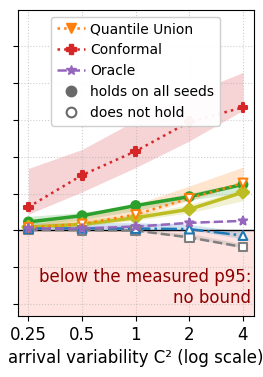

In [9]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    arrival_statistics = sweep_statistics(arrival_methods, arrival_truth, arrival_cv2s, seeds, confidence)   # name -> coverage, tightness, holds, computed
    tightness_sweep_figure(arrival_cv2s, arrival_statistics, "arrival variability C² (log scale)",
                           f"B.4b arrival variability, {data_source} data: {' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed,\n"
                           f"{gamma_arrivals}, {len(seeds)} seeds", p_label, name=f"b4b_arrivals_{data_source}", half="right")

In [10]:
if "B.4b" in skipped:
    print("B.4b skipped: not supported by the {} data".format(data_source))
else:
    cv2_label = lambda cv2: f"C² = {cv2:g}"
    display(Markdown(
        f"**What this shows** ({data_source} data, {gamma_arrivals}, ε = {alpha:g}, {len(seeds)} seeds).\n"
        + sweep_conclusion(arrival_cv2s, arrival_statistics, sweep_competitors, cv2_label) + "\n"
        + ground_truth_conclusion(arrival_cv2s, arrival_truth, arrival_statistics, seeds, cv2_label, p_label, ", at the same arrival rates")
    ))

**What this shows** (synthetic data, gamma arrivals at 4/s, ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours), Conformal. Methods that do not hold, and where: Pegasus SNC (ours) at C² = 0.25, C² = 0.5; GP Sum at every setting; GP Queue at every setting; Quantile Union at every setting.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 1.17× at C² = 0.25 to 2.38× at C² = 4; Conformal from 1.55× at C² = 0.25 to 10.15× at C² = 4.
- **Ground truth.** The measured p95 of the end-to-end latency, the median over the held-out configurations, goes from 0.23 s at C² = 0.25 to 0.34 s at C² = 4, at the same arrival rates. The Oracle, the union bound over measured services, is at 1.03× and 1.20×.